# 01 · Panorama de fuentes

Sesión 1 del **Fraud Agent Lab**. Antes de modelar miro qué trae cada fuente y en qué se parece
el fraude a lo que ya vi en el lab de crédito.

| Momento del fraude | Fuente | Unidad |
|---|---|---|
| Solicitud (onboarding) | Bank Account Fraud (Feedzai, NeurIPS 2022) | solicitud de apertura de cuenta |
| Transacción | PaySim | transacción de dinero móvil |
| Red / lavado | IBM AML HI-Small (NeurIPS 2023) | transferencia entre cuentas |

Lee `data/interim/` (todo). Para correrlo sin descargar, cambia a `db.conectar(db.PROCESSED)` y pondera por `peso`.

In [1]:
import matplotlib.pyplot as plt
from fraud_lab import db

con = db.conectar()
q = lambda sql: con.sql(sql).df()
AZUL, TINTA, SUAVE, FONDO = "#2a78d6", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": FONDO, "axes.facecolor": FONDO, "axes.edgecolor": SUAVE,
                     "axes.labelcolor": SUAVE, "xtick.color": SUAVE, "ytick.color": SUAVE,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

## 1. Bank Account Fraud: fraude de solicitud

In [2]:
q('''SELECT 'base' AS variante, count(*) AS n, avg(fraud_bool) AS tasa, count(DISTINCT month) AS meses FROM baf_base
     UNION ALL SELECT 'v1', count(*), avg(fraud_bool), count(DISTINCT month) FROM baf_v1
     UNION ALL SELECT 'v2', count(*), avg(fraud_bool), count(DISTINCT month) FROM baf_v2
     UNION ALL SELECT 'v3', count(*), avg(fraud_bool), count(DISTINCT month) FROM baf_v3
     UNION ALL SELECT 'v4', count(*), avg(fraud_bool), count(DISTINCT month) FROM baf_v4
     UNION ALL SELECT 'v5', count(*), avg(fraud_bool), count(DISTINCT month) FROM baf_v5''')

,variante,n,tasa,meses
0,base,1000000,0.011029,8
1,v1,1000000,0.011029,8
2,v2,1000000,0.011029,8
3,v3,1000000,0.011030,8
4,v4,1000000,0.011030,8
5,v5,1000000,0.011030,8


Las 6 variantes tienen la misma tasa (1,10%) pero distinto **sesgo** respecto al grupo protegido
(edad ≥ 50): tamaño del grupo, prevalencia y separabilidad. Es el banco de pruebas de fairness del lab.

In [3]:
q('''SELECT 'base' AS v, customer_age >= 50 AS mayor_50, count(*) AS n, avg(fraud_bool) AS tasa FROM baf_base GROUP BY 1, 2
     UNION ALL SELECT 'v1', customer_age >= 50, count(*), avg(fraud_bool) FROM baf_v1 GROUP BY 1, 2
     UNION ALL SELECT 'v2', customer_age >= 50, count(*), avg(fraud_bool) FROM baf_v2 GROUP BY 1, 2
     UNION ALL SELECT 'v4', customer_age >= 50, count(*), avg(fraud_bool) FROM baf_v4 GROUP BY 1, 2
     ORDER BY 1, 2''')

,v,mayor_50,n,tasa
0,base,False,816987,0.008255
1,base,True,183013,0.023414
2,v1,False,889301,0.010888
3,v1,True,110699,0.012159
4,v2,False,494153,0.003641
5,v2,True,505847,0.018247
6,v4,False,494188,0.005374
7,v4,True,505812,0.016556


In [4]:
edad = q("SELECT customer_age AS edad, avg(fraud_bool) * 100 AS tasa FROM baf_base GROUP BY 1 ORDER BY 1")
score = q('''SELECT decil, avg(fraud_bool) * 100 AS tasa, min(credit_risk_score) AS desde, max(credit_risk_score) AS hasta
             FROM (SELECT *, ntile(10) OVER (ORDER BY credit_risk_score) AS decil FROM baf_base) GROUP BY 1 ORDER BY 1''')
limite = q('''SELECT proposed_credit_limit AS limite, count(*) AS n, avg(fraud_bool) AS tasa FROM baf_base GROUP BY 1 ORDER BY 1''')
score

,decil,tasa,desde,hasta
0,1,0.545,-170,48
1,2,0.681,48,73
2,3,0.706,73,92
3,4,0.636,92,107
4,5,0.618,107,122
5,6,0.682,122,141
6,7,1.004,141,165
7,8,1.261,165,192
8,9,1.534,192,226
9,10,3.362,226,389


In [5]:
limite

,limite,n,tasa
0,190.0,163,0.006135
1,200.0,613854,0.007207
2,210.0,607,0.001647
3,490.0,870,0.013793
4,500.0,135797,0.010737
5,510.0,6967,0.004593
6,990.0,7580,0.017942
7,1000.0,81882,0.011040
8,1500.0,145735,0.021841
9,1900.0,390,0.205128


**Puente con el lab de crédito:** el fraude *sube* con el puntaje de riesgo del banco y con el límite
propuesto. Un modelo de PD ve a estos solicitantes como buenos clientes; por eso la puerta antifraude va
**antes** del motor de crédito y no se reemplaza con él.

## 2. PaySim: fraude transaccional

In [6]:
tipos = q('''SELECT type AS tipo, count(*) AS n, sum(isFraud) AS fraudes, avg(isFraud) * 100 AS tasa,
                    sum(amount) FILTER (isFraud = 1) AS monto_defraudado FROM paysim GROUP BY 1 ORDER BY n DESC''')
tipos

,tipo,n,fraudes,tasa,monto_defraudado
0,CASH_OUT,2237500,4116.0,0.183955,5.989202e+09
1,PAYMENT,2151495,0.0,0.000000,NaN
2,CASH_IN,1399284,0.0,0.000000,NaN
3,TRANSFER,532909,4097.0,0.768799,6.067213e+09
4,DEBIT,41432,0.0,0.000000,NaN


In [7]:
q('''SELECT sum(isFlaggedFraud) AS marcadas_por_regla, sum(isFlaggedFraud * isFraud) AS aciertos, sum(isFraud) AS fraudes,
          avg((newbalanceOrig = 0)::INT) FILTER (isFraud = 1) AS fraude_vacia_cuenta,
          avg((newbalanceOrig = 0)::INT) FILTER (isFraud = 0 AND type IN ('TRANSFER', 'CASH_OUT')) AS sano_vacia_cuenta
     FROM paysim''')

,marcadas_por_regla,aciertos,fraudes,fraude_vacia_cuenta,sano_vacia_cuenta
0,16.0,16.0,8213.0,0.980519,0.900951


Solo hay fraude en `TRANSFER` y `CASH_OUT`, y la regla del simulador (`isFlaggedFraud`, montos > 200 mil)
caza 16 de 8.213. Ojo: las columnas de saldo las genera el mismo simulador que el fraude, así que pueden
**filtrar la etiqueta**. Es el primer chequeo de fuga de la sesión de fraude transaccional.

## 3. IBM AML: lavado en redes

In [8]:
q('''SELECT count(*) AS transferencias, sum(es_lavado) AS lavado, avg(es_lavado) AS tasa,
          min(ts) AS desde, max(ts) AS hasta, count(DISTINCT banco_origen || cuenta_origen) AS cuentas_origen
     FROM aml_transacciones''')

,transferencias,lavado,tasa,desde,hasta,cuentas_origen
0,5078345,5177.0,0.001019,2022-09-01,2022-09-18 16:18:00,496999


In [9]:
tipologias = q('''SELECT tipologia, count(DISTINCT patron_id) AS patrones, count(*) AS transferencias
                    FROM aml_patrones GROUP BY 1 ORDER BY patrones DESC''')
tipologias

,tipologia,patrones,transferencias
0,cycle,54,287
1,gather-scatter,51,716
2,bipartite,49,263
3,fan-out,48,342
4,scatter-gather,44,626
5,stack,43,466
6,random,41,191
7,fan-in,40,318


8 tipologías (ciclo, fan-in, fan-out, gather-scatter…) cubren 3.209 de las 5.177 transferencias de lavado; el
resto es lavado sin patrón etiquetado. Un modelo por transacción no ve estas formas: hace falta mirar el **grafo**.

## 4. Resumen visual

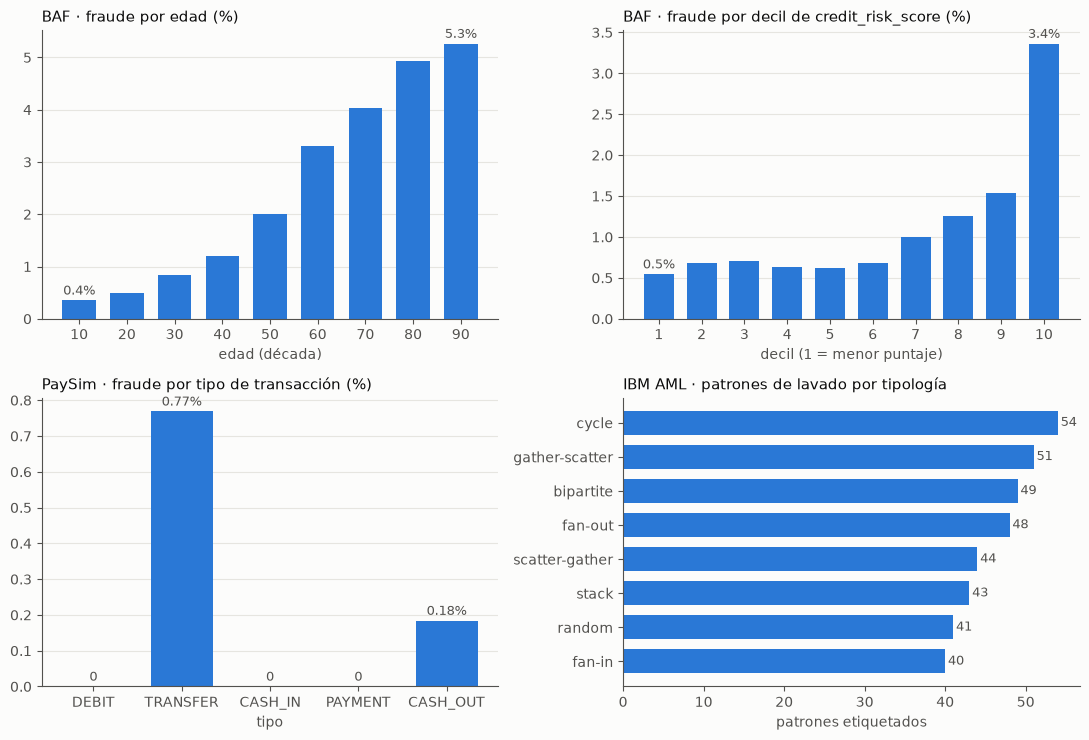

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))
def barras(a, x, y, titulo, etiqueta_x, fmt="{:.1f}%", etiquetas=None):
    b = a.bar(x, y, color=AZUL, width=0.7)
    a.set_title(titulo, loc="left", color=TINTA, fontsize=11)
    a.set_xlabel(etiqueta_x)
    a.grid(axis="y", color="#e6e5e0", linewidth=0.8); a.set_axisbelow(True)
    a.bar_label(b, labels=etiquetas or [fmt.format(v) if i in (0, len(y) - 1) else "" for i, v in enumerate(y)], color=SUAVE, fontsize=9, padding=2)

barras(ax[0, 0], edad.edad.astype(str), edad.tasa, "BAF · fraude por edad (%)", "edad (década)")
barras(ax[0, 1], score.decil.astype(str), score.tasa, "BAF · fraude por decil de credit_risk_score (%)", "decil (1 = menor puntaje)")
t = tipos.sort_values("n")
barras(ax[1, 0], t.tipo, t.tasa, "PaySim · fraude por tipo de transacción (%)", "tipo",
       etiquetas=[f"{v:.2f}%" if v > 0 else "0" for v in t.tasa])
tp = tipologias.sort_values("patrones")
b = ax[1, 1].barh(tp.tipologia, tp.patrones, color=AZUL, height=0.7)
ax[1, 1].bar_label(b, color=SUAVE, fontsize=9, padding=2)
ax[1, 1].set_title("IBM AML · patrones de lavado por tipología", loc="left", color=TINTA, fontsize=11)
ax[1, 1].set_xlabel("patrones etiquetados")
fig.tight_layout()
fig.savefig(db.RAIZ / "docs" / "img" / "panorama_fuentes.png", dpi=150)

## Mis conclusiones

1. **Fraude no es riesgo de crédito.** En BAF el fraude *sube* con el `credit_risk_score`: 0,5% en el decil más bajo y 3,4% en el más alto. Con límites propuestos de 1.900–2.100 llega al 13–20%. El defraudador se presenta como un buen cliente, así que mi motor de crédito lo aprobaría: la puerta antifraude va **antes** del modelo de PD y no se reemplaza con él.
2. **La edad va a ser mi problema de fairness.** El fraude pasa de 0,4% (20 años) a 5,3% (90). Entre mayores de 50 es 2,3% contra 0,8%. Un modelo que solo optimice recall va a castigar a los mayores, y las variantes de BAF me sirven para medir cuánto.
3. **Cada fuente pide una técnica distinta.** PaySim solo tiene fraude en `TRANSFER` y `CASH_OUT` (y debo vigilar la fuga en los saldos), e IBM AML esconde el lavado en formas de red (ciclos, fan-in, fan-out) que un modelo por transacción no ve.